# Notebook 17 — Incremental category validity: prevalence corrected for the base rate

Added November 12, 2026, in response to Keith Holyoak. Counting only: no language model is called and nothing upstream changes. Outputs go to `v4_rebuild/17_category_utility/`.

**The measure.** Keith suggested incremental category validity, the core term of Gluck and Corter's category utility (Gluck & Corter, 1985; Corter & Gluck, 1992): the probability of a feature given the category minus its probability given the superordinate. For a feature e and genre g, with all films as the superordinate,

CU(e, g) = P(e | g) − P(e | film).

So for the town in Westerns it is the share of Westerns with a town minus the share of all films with a town. It is prevalence with the feature's base rate in film subtracted.

**How it relates to the two numbers.** Prevalence is P(e | g) and distinctiveness is P(g | e). By Bayes' rule, P(e | g) ÷ P(e) = P(g | e) ÷ P(g): the ratio of prevalence to the base rate is distinctiveness scaled by the genre's size. Incremental category validity is the difference of the same two quantities rather than their ratio. Two consequences follow before any data are counted.

1. Within one genre, across features, it ranks differently from both numbers. A feature in half of all Westerns and 40% of all films gains 0.10; one in 5% of Westerns and 0.1% of films gains about 0.05. It rewards features that are both common in the genre and more common there than in film, the "high on both" corner, in one number on the probability scale.
2. For one feature, across genres, it ranks genres exactly as prevalence does, because the subtracted base rate is the same for every genre. So the test of whether the court's genre is the feature's best genre gives the same answer for incremental category validity as for prevalence.

**What this notebook counts.** (A) how incremental category validity correlates with the six scores the pipeline already computes, and whose top-50 lists it shares; (B) the top features of three genres on prevalence, incremental category validity and distinctiveness, with a picture of the Western; (C) where court-named features fall on it; (D) how it moves over time for the sheriff, the alien and the ghost, the three features of the talk's time slides.

In [1]:
import shutil, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/'
         'My Drive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path.cwd() / 'v4_rebuild',
    Path.cwd().parent / 'v4_rebuild',
]
V4 = next((c for c in _CANDS if c.exists()), None)
assert V4 is not None, 'Could not locate v4_rebuild; set V4 manually.'
OUT = V4 / '17_category_utility'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)

plt.rcdefaults()
plt.rcParams.update({'font.size': 10, 'savefig.facecolor': 'white'})
BLUE, RED, GRAY = '#1f77b4', '#d62728', '#7f7f7f'
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', dpi=200, facecolor='white')
    plt.show()

report = []
def out(s=''):
    print(s); report.append(s)
print('V4 =', V4)

V4 = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild


## Load the counts

The scored table gives prevalence (`rel_freq_in_genre`, films of the genre with the feature ÷ films of the genre). The base rate needs the number of distinct films with the feature, which the scored table does not carry (its `total_film_count` sums over genre tags, so a film tagged Western and Drama counts twice). It is counted here from the feature index: distinct films with the feature ÷ all 45,958 films.

In [2]:
cls = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet')
films = read_parquet(V4 / '01c_union' / 'movies_union.parquet', columns=['union_id'])
N_FILMS = films['union_id'].nunique()
idx = read_parquet(V4 / '02_elements' / 'element_index.parquet').drop_duplicates()
n_e = idx.groupby(['element', 'element_type'])['union_id'].nunique().rename('films_with_element').reset_index()
cls = cls.merge(n_e, on=['element', 'element_type'], how='left')
assert cls['films_with_element'].notna().all()
cls['base_rate'] = cls['films_with_element'] / N_FILMS
cls['category_utility'] = cls['rel_freq_in_genre'] - cls['base_rate']
GEN = sorted(cls['genre'].unique())
narr = cls[cls['is_narrative_element']].copy()
out('NOTEBOOK 17 — INCREMENTAL CATEGORY VALIDITY, P(e | genre) − P(e | film)')
out(f'{N_FILMS:,} films; {len(cls):,} cells; {len(narr):,} narrative cells in {len(GEN)} genres')
out(f"Share of narrative cells with incremental category validity above zero: {(narr['category_utility'] > 0).mean():.3f}")
narr[['element', 'element_type', 'genre', 'film_count', 'films_with_element', 'rel_freq_in_genre', 'base_rate', 'category_utility']].head()

NOTEBOOK 17 — INCREMENTAL CATEGORY VALIDITY, P(e | genre) − P(e | film)
45,958 films; 345,366 cells; 237,516 narrative cells in 17 genres
Share of narrative cells with incremental category validity above zero: 0.584


,element,element_type,genre,film_count,films_with_element,rel_freq_in_genre,base_rate,category_utility
0,747,entity_PRODUCT,Action,12,14,0.001543,0.000305,0.001239
1,747,entity_PRODUCT,Adventure,8,14,0.001302,0.000305,0.000997
2,747,entity_PRODUCT,Comedy,2,14,0.000136,0.000305,-0.000169
3,747,entity_PRODUCT,Crime,2,14,0.000359,0.000305,0.000055
4,747,entity_PRODUCT,Drama,3,14,0.000134,0.000305,-0.000170


## Part A. How it relates to the scores the pipeline already has

Spearman correlation inside each genre among story features, averaged over the 17 genres; and for each genre, how many of incremental category validity's 50 highest story features are also among the 50 highest on each other score, averaged over genres.

In [3]:
MEASURES = {'prevalence': 'rel_freq_in_genre', 'distinctiveness': 'posterior_smoothed',
            'collocation': 'primary_stockiness', 'TF-IDF': 'tfidf', 'G²': 'dunning_g2_positive',
            'composite': 'ensemble', 'base rate': 'base_rate'}
rho, overlap = {k: [] for k in MEASURES}, {k: [] for k in MEASURES}
for g, d in narr.groupby('genre'):
    cu_rank = d['category_utility'].rank()
    top_cu = set(d.nlargest(50, 'category_utility').index)
    for k, col in MEASURES.items():
        rho[k].append(cu_rank.corr(d[col].rank()))
        overlap[k].append(len(top_cu & set(d.nlargest(50, col).index)))
rel = pd.DataFrame({'mean_spearman_with_cu': {k: np.mean(v) for k, v in rho.items()},
                    'mean_top50_shared_with_cu': {k: np.mean(v) for k, v in overlap.items()}})
rel.to_csv(OUT / 'cu_vs_other_scores.csv')
out(''); out('A. INCREMENTAL CATEGORY VALIDITY AGAINST THE OTHER SCORES (story features, mean over 17 genres)')
out(rel.round(2).to_string())


A. INCREMENTAL CATEGORY VALIDITY AGAINST THE OTHER SCORES (story features, mean over 17 genres)
                 mean_spearman_with_cu  mean_top50_shared_with_cu
prevalence                        0.39                      25.35
distinctiveness                   0.87                       0.18
collocation                       0.64                      35.65
TF-IDF                            0.43                      26.18
G²                                0.81                      28.76
composite                         0.83                      33.88
base rate                        -0.08                      14.65


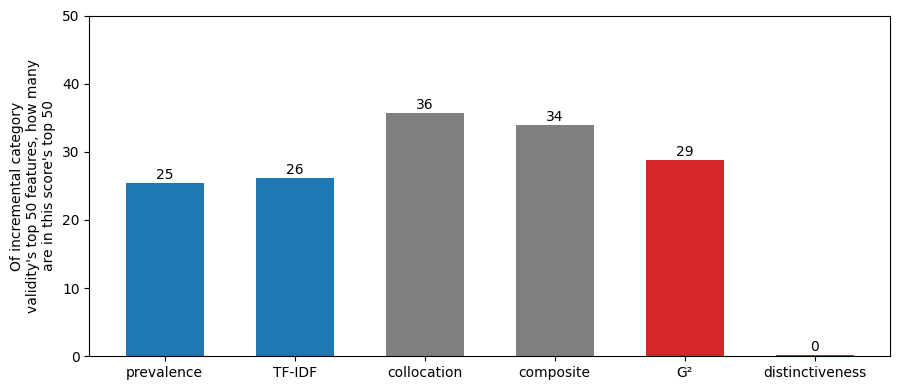

In [4]:
order = ['prevalence', 'TF-IDF', 'collocation', 'composite', 'G²', 'distinctiveness']
vals = rel.loc[order, 'mean_top50_shared_with_cu']
fig, ax = plt.subplots(figsize=(9.1, 4))
colors = [BLUE if k in ('prevalence', 'TF-IDF') else RED if k in ('distinctiveness', 'G²') else GRAY for k in order]
ax.bar(range(len(order)), vals, color=colors, width=0.6)
for i, v in enumerate(vals):
    ax.annotate(f'{v:.0f}', (i, v), textcoords='offset points', xytext=(0, 3), ha='center')
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylim(0, 50); ax.set_ylabel("Of incremental category\nvalidity's top 50 features, how many\nare in this score's top 50")
save(fig, 'cu_top50_overlap')

## Part B. What it puts at the top

Top 12 story features (each string listed once) in three genres on prevalence, incremental category validity and distinctiveness. Then a picture of the Western: each dot is a feature, placed by its share of all films (across) and its share of Westerns (up). The diagonal is "as common in Westerns as in film generally"; a feature's incremental category validity is its height above the diagonal.

In [5]:
def top(d, col, k=12):
    # a feature string filed under two grammatical types (e.g. 'earth' as noun and as entity) is listed once
    return d.sort_values(col, ascending=False).drop_duplicates('element').head(k)['element'].tolist()
for g in ['Western', 'Horror', 'Science Fiction']:
    d = narr[narr['genre'] == g]
    t = pd.DataFrame({'prevalence': top(d, 'rel_freq_in_genre'), 'category utility': top(d, 'category_utility'),
                      'distinctiveness': top(d, 'posterior_smoothed')}, index=range(1, 13))
    t.to_csv(OUT / f"top12_{g.replace(' ', '_').lower()}.csv")
    out(''); out(f'B. TOP 12 NARRATIVE ELEMENTS, {g.upper()}'); out(t.to_string())


B. TOP 12 NARRATIVE ELEMENTS, WESTERN
   prevalence category utility distinctiveness
1        kill             town     new marshal
2        town            shoot         apaches
3       shoot            horse   local rancher
4      return             kill         outdraw
5      arrive            ranch           apach
6        lead          sheriff      gunfighter
7      escape           indian           sioux
8         set             gang         rustler
9       horse           outlaw  cattle rustler
10        run              gun   indian attack
11   discover             ride     wagon train
12      learn           saloon    town marshal

B. TOP 12 NARRATIVE ELEMENTS, HORROR
   prevalence category utility   distinctiveness
1        kill             kill       lycanthropy
2    discover           attack  paranormal event
3       death            death    female vampire
4      escape           escape         vampirism
5         die         discover  malevolent force
6       house     

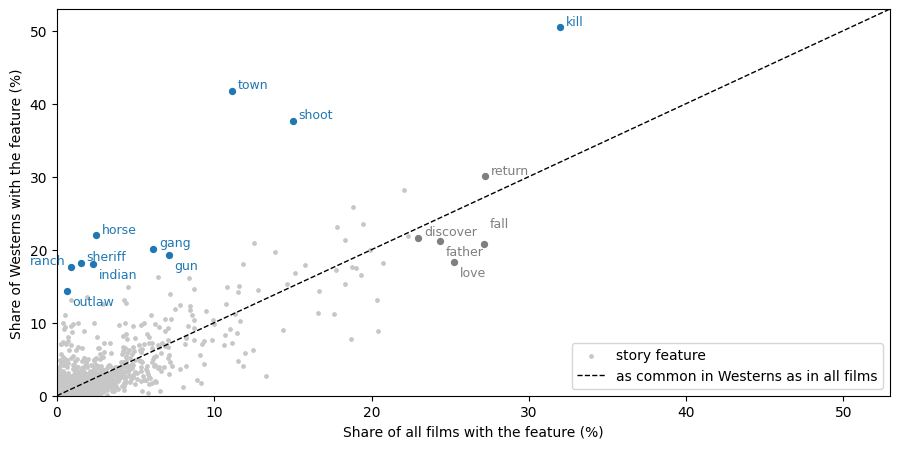

In [6]:
d = narr[narr['genre'] == 'Western'].copy()
fig, ax = plt.subplots(figsize=(9.1, 4.6))
ax.scatter(d['base_rate'] * 100, d['rel_freq_in_genre'] * 100, s=6, color='#c7c7c7', label='story feature')
lim = max(d['base_rate'].max(), d['rel_freq_in_genre'].max()) * 100 * 1.05
ax.plot([0, lim], [0, lim], color='black', ls='--', lw=1, label='as common in Westerns as in all films')
lab = pd.concat([d.nlargest(10, 'category_utility'), d.nlargest(6, 'base_rate')]).drop_duplicates('element')
hi = set(d.nlargest(10, 'category_utility')['element'])
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
fig.canvas.draw(); renderer = fig.canvas.get_renderer(); placed = []
for r in lab.sort_values('rel_freq_in_genre', ascending=False).itertuples():
    c = BLUE if r.element in hi else GRAY
    xy = (r.base_rate * 100, r.rel_freq_in_genre * 100)
    ax.scatter(*xy, s=18, color=c, zorder=3)
    # try a few label positions around the point and keep the first that overlaps no earlier label
    for dx, dy, ha in [(4, 2, 'left'), (4, -10, 'left'), (-4, 2, 'right'), (-4, -10, 'right'), (4, 12, 'left'), (-4, 12, 'right')]:
        t = ax.annotate(r.element, xy, textcoords='offset points', xytext=(dx, dy), ha=ha, fontsize=9, color=c)
        bb = t.get_window_extent(renderer).expanded(1.05, 1.1)
        if not any(bb.overlaps(o) for o in placed):
            placed.append(bb); break
        t.remove()
    else:
        t = ax.annotate(r.element, xy, textcoords='offset points', xytext=(4, 2), fontsize=9, color=c)
ax.set_xlabel('Share of all films with the feature (%)'); ax.set_ylabel('Share of Westerns with the feature (%)')
ax.legend(loc='lower right')
save(fig, 'cu_western_scatter')

## Part C. Court-named features

The strict court set of Notebook 07c (the court's own words: exact and phrase matches; the 15 event matches are left out because events have no base rate in this table). Percentiles are within (genre, grammatical type) on the feature's best-type row, exactly as in 07b and 07c, so the prevalence and distinctiveness percentiles here should reproduce 07c's. The top-genre test is not repeated: for one feature, incremental category validity orders genres exactly as prevalence does (checked below).

In [7]:
stk = cls.copy()
for name, col in [('p_prevalence', 'rel_freq_in_genre'), ('p_distinctiveness', 'posterior_smoothed'), ('p_cu', 'category_utility')]:
    stk[name] = stk.groupby(['genre', 'element_type'])[col].rank(pct=True)
best = stk.sort_values('ensemble').groupby(['element', 'genre']).tail(1).set_index(['element', 'genre'])
sm = read_parquet(V4 / '07c_court_matcher_v2' / 'scored_matches_v2.parquet')
strict = sm[sm['tier'].isin(['exact', 'phrase']) & (sm['unit'] == 'element')].copy()
keys = list(zip(strict['match'], strict['gen']))
strict = strict[[k in best.index for k in keys]].copy()
got = best.loc[list(zip(strict['match'], strict['gen'])), ['p_prevalence', 'p_distinctiveness', 'p_cu']].to_numpy()
strict[['my_p_prev', 'my_p_dist', 'p_cu']] = got
assert np.allclose(strict['my_p_prev'], strict['p_prevalence']) and np.allclose(strict['my_p_dist'], strict['p_distinctiveness'])
by_case = strict.groupby('case')[['p_prevalence', 'p_distinctiveness', 'p_cu']].median()
top_q = (strict[['p_prevalence', 'p_distinctiveness', 'p_cu']] >= 0.75).mean()
out(''); out(f"C. COURT-NAMED ELEMENTS (07c strict set, features only: {len(strict)} matches, {strict['case'].nunique()} cases)")
out('Median within-genre percentile, case medians:  ' + '   '.join(f'{k} {v:.3f}' for k, v in by_case.median().items()))
out('Share of features in the top quarter:           ' + '   '.join(f'{k} {v:.3f}' for k, v in top_q.items()))
# For one feature, CU and prevalence order the genres identically:
chk = cls.groupby(['element', 'element_type']).apply(lambda x: x['rel_freq_in_genre'].rank().equals(x['category_utility'].rank()), include_groups=False)
out(f'Features whose genre ordering is the same on incremental category validity and prevalence: {chk.mean():.4f}')


C. COURT-NAMED ELEMENTS (07c strict set, features only: 118 matches, 44 cases)
Median within-genre percentile, case medians:  p_prevalence 0.860   p_distinctiveness 0.750   p_cu 0.799
Share of features in the top quarter:           p_prevalence 0.686   p_distinctiveness 0.559   p_cu 0.627


Features whose genre ordering is the same on incremental category validity and prevalence: 1.0000


## Part D. Over time: the sheriff, the alien and the ghost

Same five-year periods and the same rule as Notebook 14 Part C (at least 30 films of the genre and 5 films with the feature in the period). In each period incremental category validity is the share of the genre's films with the feature minus the share of all the period's films with it. Medians over periods before 1970 and from 1990 on.

In [8]:
bins = read_parquet(V4 / '08_temporal' / 'stockiness_by_bin.parquet',
                    columns=['element', 'element_type', 'genre', 'bin', 'film_count', 'total_film_count', 'N_bg', 'N_bin'])
TRIO = [('sheriff', 'Western'), ('alien', 'Science Fiction'), ('ghost', 'Horror')]
MIN_BIN_FILMS, MIN_E_FILMS = 30, 5
rows = []
for el, g in TRIO:
    d = bins[(bins['element'] == el) & (bins['genre'] == g) & (bins['element_type'] == 'noun')]
    d = d[(d['N_bg'] >= MIN_BIN_FILMS) & (d['total_film_count'] >= MIN_E_FILMS)].sort_values('bin')
    for r in d.itertuples():
        prev, base = r.film_count / r.N_bg, r.total_film_count / r.N_bin
        rows.append({'element': el, 'genre': g, 'bin': int(r.bin), 'prevalence': prev, 'base_rate': base,
                     'category_utility': prev - base, 'distinctiveness': r.film_count / r.total_film_count,
                     'genre_share': r.N_bg / r.N_bin})
cu_t = pd.DataFrame(rows)
cu_t.to_csv(OUT / 'cu_over_time.csv', index=False)
eras = []
for (el, g), d in cu_t.groupby(['element', 'genre'], sort=False):
    for era, dd in [('before 1970', d[d['bin'] < 1970]), ('from 1990 on', d[d['bin'] >= 1990])]:
        eras.append({'element': el, 'genre': g, 'era': era, 'periods': len(dd), **dd[['prevalence', 'base_rate', 'category_utility', 'distinctiveness', 'genre_share']].median().to_dict()})
eras = pd.DataFrame(eras)
eras.to_csv(OUT / 'cu_before_after.csv', index=False)
out(''); out('D. MEDIANS OVER FIVE-YEAR PERIODS, BEFORE 1970 AND FROM 1990 ON')
out(eras.round(3).to_string(index=False))


D. MEDIANS OVER FIVE-YEAR PERIODS, BEFORE 1970 AND FROM 1990 ON
element           genre          era  periods  prevalence  base_rate  category_utility  distinctiveness  genre_share
sheriff         Western  before 1970        8       0.197      0.023             0.175            0.606        0.067
sheriff         Western from 1990 on        4       0.162      0.012             0.148            0.138        0.010
  alien Science Fiction  before 1970        4       0.119      0.007             0.112            0.932        0.067
  alien Science Fiction from 1990 on        6       0.122      0.011             0.111            0.698        0.066
  ghost          Horror  before 1970        6       0.043      0.012             0.033            0.218        0.052
  ghost          Horror from 1990 on        6       0.126      0.024             0.101            0.544        0.101


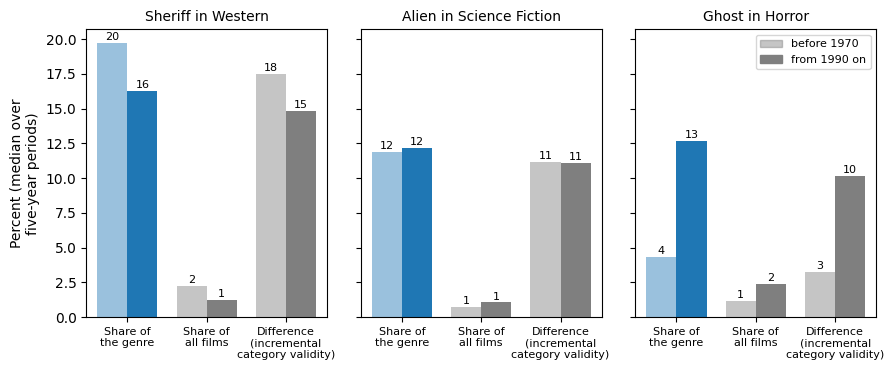

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(9.1, 3.8), sharey=True)
for ax, (el, g) in zip(axes, TRIO):
    d = eras[eras['element'] == el].set_index('era')
    x = np.arange(3); w = 0.38
    for j, (era, alpha) in enumerate([('before 1970', 0.45), ('from 1990 on', 1.0)]):
        v = [100 * d.loc[era, c] for c in ['prevalence', 'base_rate', 'category_utility']]
        bars = ax.bar(x + (j - 0.5) * w, v, w, color=[BLUE, GRAY, GRAY], alpha=alpha, label=era)
        for xi, vi in zip(x + (j - 0.5) * w, v):
            ax.annotate(f'{vi:.0f}', (xi, vi), textcoords='offset points', xytext=(0, 2), ha='center', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(['Share of\nthe genre', 'Share of\nall films', 'Difference\n(incremental\ncategory validity)'], fontsize=8)
    ax.set_title(f'{el.capitalize()} in {g}', fontsize=10)
axes[0].set_ylabel('Percent (median over\nfive-year periods)')
from matplotlib.patches import Patch
axes[-1].legend(handles=[Patch(color=GRAY, alpha=0.45, label='before 1970'), Patch(color=GRAY, label='from 1990 on')], loc='upper right', fontsize=8)
save(fig, 'cu_before_after')

## Part E. Incremental category validity for the Study 1 items

The exploratory Study 1 test (`study1_analysis/study1_exploratory_category_utility.Rmd`) needs incremental category validity for every feature in the Study 1 pool, scaled the way the registered predictors were: as a percentile rank within genre over the whole eligible pool (notebook 10). The cell checks that the same rule reproduces the registered prevalence and distinctiveness percentiles before it writes the new column.

In [10]:
pool = pd.read_csv(V4 / '10_human_study_stimuli' / 'eligible_pool_predictors.csv')
pool = pool.merge(cls[['genre', 'element', 'element_type', 'category_utility', 'base_rate']],
                  on=['genre', 'element', 'element_type'], how='left', validate='one_to_one')
assert pool['category_utility'].notna().all()
assert np.allclose(pool.groupby('genre')['rel_freq_in_genre'].rank(pct=True), pool['prevalence_pct'])
assert np.allclose(pool.groupby('genre')['posterior_smoothed'].rank(pct=True), pool['distinctiveness_pct'])
pool['cu_pct'] = pool.groupby('genre')['category_utility'].rank(pct=True)
pool[['genre', 'key', 'element', 'element_type', 'category_utility', 'base_rate', 'cu_pct']].to_csv(OUT / 'cu_pool_predictors.csv', index=False)
ga = pool[pool['in_generation_analysis_set']]
rho = ga.groupby('genre').apply(lambda d: pd.Series({
    'with prevalence': d['cu_pct'].corr(d['prevalence_pct'], method='spearman'),
    'with distinctiveness': d['cu_pct'].corr(d['distinctiveness_pct'], method='spearman'),
    'with composite': d['cu_pct'].corr(d['ensemble_pct'], method='spearman')}), include_groups=False)
out(''); out(f'E. STUDY 1 POOL: {len(pool):,} rows, {len(ga):,} in the generation analysis set; Spearman of the incremental category validity percentile, by genre')
out(rho.round(2).to_string())


E. STUDY 1 POOL: 8,972 rows, 8,816 in the generation analysis set; Spearman of the incremental category validity percentile, by genre
                 with prevalence  with distinctiveness  with composite
genre                                                                 
Comedy                      0.03                  0.90            0.70
Crime                       0.35                  0.90            0.82
Fantasy                     0.50                  0.81            0.86
Horror                      0.46                  0.80            0.85
Science Fiction             0.43                  0.84            0.81
Western                     0.41                  0.91            0.78


## Part F. Incremental category validity and incremental cue validity (Keith Holyoak, November 13, 2026)

Keith calls the measure of this notebook incremental category validity, ΔCatV = P(F | C) − P(F | S), with S all films. The matching increment on the other side is incremental cue validity, ΔCue = P(C | F) − P(C). Bayes' rule links them, and multiplying through gives one identity:

P(C) · ΔCatV = P(F) · ΔCue = P(F and C) − P(F) · P(C).

Both increments are the same covariance between feature and genre, divided by the base rate of what is conditioned on. Within one genre P(C) is fixed, so ranking features by ΔCatV is ranking them by that covariance; ΔCue divides by the feature's base rate P(F), which varies from feature to feature, so the two rank features differently even though each is proportional to the other feature by feature. This part checks the identity on the counts, gives the town in Westerns with the real numbers, and measures how each increment ranks features against the pipeline's two measures. It also computes the contrast version, P(F | C) − P(F | not C), which compares the genre with all other films instead of all films.

In [11]:
N = N_FILMS
d = cls.copy()
d['n_genre'] = d['film_count'] / d['rel_freq_in_genre']                      # films of the genre
d['p_c'] = d['n_genre'] / N                                                   # P(C)
d['p_f'] = d['films_with_element'] / N                                        # P(F)
d['p_fc'] = d['film_count'] / N                                               # P(F and C)
d['dcatv'] = d['rel_freq_in_genre'] - d['p_f']                                # P(F|C) - P(F)
d['p_c_given_f'] = d['film_count'] / d['films_with_element']                  # raw cue validity P(C|F), distinct films
d['dcue'] = d['p_c_given_f'] - d['p_c']                                       # P(C|F) - P(C)
d['covariance'] = d['p_fc'] - d['p_f'] * d['p_c']
d['contrast'] = d['rel_freq_in_genre'] - (d['films_with_element'] - d['film_count']) / (N - d['n_genre'])   # P(F|C) - P(F|not C)
assert np.allclose(d['p_c'] * d['dcatv'], d['covariance']) and np.allclose(d['p_f'] * d['dcue'], d['covariance'])
out(''); out('F. INCREMENTAL CATEGORY VALIDITY AND INCREMENTAL CUE VALIDITY')
out('Identity P(C)*dCatV = P(F)*dCue = P(F and C) - P(F)P(C): holds on every cell (checked numerically)')
t = d[(d.genre == 'Western') & (d.element == 'town') & (d.element_type == 'noun')].iloc[0]
out(f"Town in Westerns: P(F|C) = {t.rel_freq_in_genre:.3f}, P(F) = {t.p_f:.3f}, P(C) = {t.p_c:.4f} ({int(round(t.n_genre)):,} of {N:,} films)")
out(f"  dCatV = {t.dcatv:.3f};  P(C|F) = {t.p_c_given_f:.3f};  dCue = {t.dcue:.3f};  covariance = {t.covariance:.4f};  contrast P(F|C) - P(F|not C) = {t.contrast:.3f}")
nar = d[d['is_narrative_element']]
rows = []
for g, x in nar.groupby('genre'):
    r = lambda a, b: x[a].rank().corr(x[b].rank())
    rows.append({'genre': g, 'dCatV~contrast': r('dcatv', 'contrast'), 'dCatV~covariance': r('dcatv', 'covariance'),
                 'dCue~distinctiveness': r('dcue', 'posterior_smoothed'), 'dCue~dCatV': r('dcue', 'dcatv'),
                 'dCue~prevalence': r('dcue', 'rel_freq_in_genre')})
rk = pd.DataFrame(rows).set_index('genre')
rk.to_csv(OUT / 'increment_rank_correlations.csv')
out('Within-genre Spearman correlations among story features, mean over the 17 genres (min, max):')
for c in rk.columns:
    out(f'  {c:<24} {rk[c].mean():.3f}  ({rk[c].min():.3f}, {rk[c].max():.3f})')
top = lambda x, col: set(x.nlargest(50, col).index)
ov = pd.DataFrame([{'genre': g, 'dCue_top50_shared_with_distinctiveness': len(top(x, 'dcue') & top(x, 'posterior_smoothed')),
                    'dCue_top50_shared_with_dCatV': len(top(x, 'dcue') & top(x, 'dcatv'))} for g, x in nar.groupby('genre')])
out(f"Top 50 by dCue: shared with distinctiveness's top 50 {ov.iloc[:, 1].mean():.1f}, with dCatV's top 50 {ov.iloc[:, 2].mean():.1f} (mean over genres)")
rk.round(3)


F. INCREMENTAL CATEGORY VALIDITY AND INCREMENTAL CUE VALIDITY
Identity P(C)*dCatV = P(F)*dCue = P(F and C) - P(F)P(C): holds on every cell (checked numerically)
Town in Westerns: P(F|C) = 0.417, P(F) = 0.112, P(C) = 0.0296 (1,362 of 45,958 films)
  dCatV = 0.305;  P(C|F) = 0.111;  dCue = 0.081;  covariance = 0.0091;  contrast P(F|C) - P(F|not C) = 0.315


Within-genre Spearman correlations among story features, mean over the 17 genres (min, max):
  dCatV~contrast           1.000  (1.000, 1.000)
  dCatV~covariance         1.000  (1.000, 1.000)
  dCue~distinctiveness     0.999  (0.998, 1.000)
  dCue~dCatV               0.858  (0.799, 0.888)
  dCue~prevalence          0.311  (0.075, 0.459)


Top 50 by dCue: shared with distinctiveness's top 50 44.5, with dCatV's top 50 0.1 (mean over genres)


,dCatV~contrast,dCatV~covariance,dCue~distinctiveness,dCue~dCatV,dCue~prevalence
genre,,,,,
Action,1.0,1.0,0.999,0.865,0.459
Adventure,1.0,1.0,0.999,0.846,0.442
Animation,1.0,1.0,0.999,0.854,0.295
Comedy,1.0,1.0,0.999,0.855,0.399
Crime,1.0,1.0,0.999,0.886,0.406
Drama,1.0,1.0,0.998,0.860,0.361
Family,1.0,1.0,0.999,0.874,0.335
Fantasy,1.0,1.0,0.999,0.799,0.247
History,1.0,1.0,0.999,0.821,0.237


## Outputs

In [12]:
(OUT / 'category_utility_report.txt').write_text('\n'.join(report) + '\n')
cls[['element', 'element_type', 'genre', 'films_with_element', 'base_rate', 'category_utility']].to_parquet(OUT / 'category_utility_cells.parquet', index=False)
print(sorted(p.name for p in OUT.rglob('*') if p.is_file()))

['category_utility_cells.parquet', 'category_utility_report.txt', 'cu_before_after.csv', 'cu_before_after.png', 'cu_over_time.csv', 'cu_pool_predictors.csv', 'cu_top50_overlap.png', 'cu_vs_other_scores.csv', 'cu_western_scatter.png', 'increment_rank_correlations.csv', 'top12_horror.csv', 'top12_science_fiction.csv', 'top12_western.csv']
